In [1]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from einops import rearrange
import matplotlib.cm as cm
import numpy as np
import pickle
import torch
import math
import sys

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.fourier import isotropic_power_spectrum
from waveletflux.utils.well_data import get_well_dataset
from waveletflux.utils.plot import draw_movie, plot_psd, field2rgb
from waveletflux.utils.rollout import get_gt_frame, get_pred_frame
from waveletflux.utils.eval import build_stats_df

#well_dataset_name = 'turbulent_radiative_layer_2D'
well_dataset_name = 'rayleigh_benard'
#well_dataset_name = 'planetswe'
#well_dataset_name = 'active_matter'

RESULT_DIR = f"{PROJECT_ROOT}/experiments/{well_dataset_name}/results"

In [2]:
well_base_path = f"{PROJECT_ROOT}/data/datasets"

dataset = get_well_dataset(
    path=well_base_path,
    physics=well_dataset_name,
    split='test',
    steps=-1,
    transform = ['log_scalars'],   
    augment = [],
)

meta_fields = dataset.metadata.field_names
field_names = [item for sublist in meta_fields.values() for item in sublist]

In [3]:
model_paths = {
    "FM-DS"                 : f'{RESULT_DIR}/FM_data_space_v4.0_nsampling50_nens1_{well_dataset_name}_traj.pkl',
    "WaveletFM-1scale"      : f'{RESULT_DIR}/WaveletFlow_1scale_db2_v4.0_nsampling50_nens1_{well_dataset_name}_traj.pkl',
    "WaveletFM-3scales"      : f'{RESULT_DIR}/WaveletFlow_3scales_db2_v4.0_nsampling50_nens1_{well_dataset_name}_traj.pkl',
    "UNetClassic"            : f'{RESULT_DIR}/UNetClassic_rollout_{well_dataset_name}_traj.pkl',
    #"UNetConvNext"           : f'{RESULT_DIR}/UNetConvNext_rollout_{well_dataset_name}_traj.pkl',
    "FNO"                    : f'{RESULT_DIR}/FNO_rollout_{well_dataset_name}_traj.pkl',
    #"WNO"                    : f'{RESULT_DIR}/WNO_rollout_{well_dataset_name}_traj.pkl',
    "TFNO"                   : f'{RESULT_DIR}/TFNO_rollout_{well_dataset_name}_traj.pkl',
}

# model data
rollout_traj = {}
for model, path in model_paths.items():
    with open(path, 'rb') as f:
        data = pickle.load(f)
        if type(data) == dict:
             f.seek(0)  # Reset file pointer to the beginning
             rollout_traj[model] = data['preds']
        else:
            rollout_traj[model] = data
    print(f"Loaded rollout trajectory for {model}")

# ground truth data
with open(f'{RESULT_DIR}/ground_truth_{well_dataset_name}_traj.pkl', 'rb') as f:
    truth_traj = pickle.load(f)
    print("Loaded ground truth trajectory")


models_to_plot = [
    "FM-DS",
    "WaveletFM-1scale",
    "WaveletFM-3scales", 
    "UNetClassic", 
    #"UNetConvNext", 
    "FNO", 
    #"WNO", 
    "TFNO"
    ]


Loaded rollout trajectory for FM-DS
Loaded rollout trajectory for WaveletFM-1scale
Loaded rollout trajectory for WaveletFM-3scales
Loaded rollout trajectory for UNetClassic
Loaded rollout trajectory for FNO
Loaded rollout trajectory for TFNO
Loaded ground truth trajectory


In [6]:
rollout_traj.keys()

dict_keys(['FM-DS', 'WaveletFM-1scale', 'WaveletFM-3scales', 'UNetClassic', 'FNO', 'TFNO'])

In [ ]:
print(rollout_traj['WaveletFM-3scales'].shape)
print(rollout_traj['UNetClassic'].shape)
print(truth_traj.shape)

# Graphical Abstract

In [12]:
from waveletflux.utils.plot import draw

In [13]:
field = 0
frames = np.array([0, 16, 32, 48, 64, 128])

for model_name, traj in rollout_traj.items():

    print(f"Model: {model_name}")
    print(f"Trajectory shape: {traj.shape}")


    x = traj[:, 0, frames, ..., field]
    print(f"Selected frame shape: {x.shape}")

    vmin = np.nanquantile(x, 0.01, keepdims=True) - 1e-2
    vmax = np.nanquantile(x, 0.99, keepdims=True) + 1e-2

    draw(x, vmin=vmin, vmax=vmax, pad=8) #.save(outdir / f"rb_{i}_gt.png")

    ##for i, file in enumerate(files):
    #    x, x_hat = np.load(file).values()
#
    #    x = x[field, frames, ::2, :]
    #    x_hat = x_hat[:, field, frames, ::2, :]
#
    #    vmin = np.nanquantile(x, 0.01, keepdims=True) - 1e-2
    #    vmax = np.nanquantile(x, 0.99, keepdims=True) + 1e-2
#
    #    draw(x, vmin=vmin, vmax=vmax, pad=8).save(outdir / f"rb_{i}_gt.png")
#
    #    for j in range(len(x_hat)):
    #        draw(x_hat[j], vmin=vmin, vmax=vmax, pad=8).save(outdir / f"rb_{i}_{method}_{compression:04d}_{j}.png")

Model: FM-DS
Trajectory shape: (9, 1, 196, 512, 128, 4)
Selected frame shape: (6, 9, 512, 128)
Model: WaveletFM-1scale
Trajectory shape: (9, 1, 196, 512, 128, 4)
Selected frame shape: (6, 9, 512, 128)
Model: WaveletFM-3scales
Trajectory shape: (9, 1, 196, 512, 128, 4)
Selected frame shape: (6, 9, 512, 128)
Model: UNetClassic
Trajectory shape: torch.Size([9, 196, 512, 128, 4])
Selected frame shape: torch.Size([9, 6, 128])
Model: FNO
Trajectory shape: torch.Size([9, 196, 512, 128, 4])
Selected frame shape: torch.Size([9, 6, 128])
Model: TFNO
Trajectory shape: torch.Size([9, 196, 512, 128, 4])
Selected frame shape: torch.Size([9, 6, 128])


# Benchmark Plot across Rollout Steps

In [32]:
models_to_plot

['FM-DS',
 'WaveletFM-1scale',
 'WaveletFM-3scales',
 'UNetClassic',
 'FNO',
 'TFNO']

In [61]:
models_to_plot_ = [
                'WaveletFM-3scales',
                'FM-DS',
                #'WaveletFM-1scale',
                'UNetClassic',
                # #'FNO',
                # #'TFNO'
                   ]

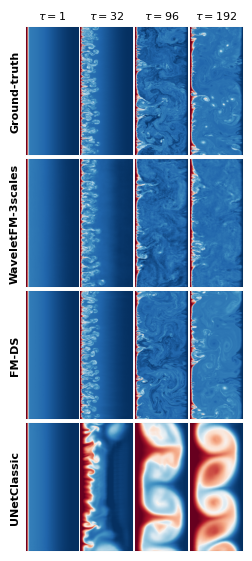

In [66]:
TRAJ_IDX        = 0
ENS_IDX         = 0
N_STEPS_INPUT   = 4
field_idx       = 0
field_name      = field_names[field_idx]
T_TOTAL         = dataset.metadata.n_steps_per_trajectory[0]
N_ROLLOUT_STEPS = T_TOTAL - N_STEPS_INPUT
N_TRAJ          = len(dataset.metadata.n_steps_per_trajectory)                  # number of trajectories in the test set for this PDE

#lead_times = [1, 16, 32, 48, 64, 80, 96]
#lead_times = [1, 16, 32, 48, 64, 80, 96]
#lead_times = [1, 32, 64, 96, 128, 160, 192]
#lead_times = [1, 10, 20, 30, 40, 45]
#lead_times = [1, 3, 6, 10, 16, 24]
lead_times = [1, 32, 96, 192]

gt_frames = [get_gt_frame(truth_traj, TRAJ_IDX, t, N_STEPS_INPUT, field_idx) for t in lead_times]
model_frames = {
    name: [get_pred_frame(rollout_traj[name], TRAJ_IDX, ENS_IDX, t, field_idx) for t in lead_times]
    for name in models_to_plot_
}

row_labels     = ["Ground-truth"] + models_to_plot_
all_row_frames = [gt_frames] + [model_frames[name] for name in models_to_plot_]
n_rows, n_cols = len(row_labels), len(lead_times)

# ── Compute vmin/vmax from the GROUND TRUTH row only ─────────────────────────
gt_vals = np.concatenate([f.ravel() for f in gt_frames])

gt_vmin = float(np.percentile(gt_vals, 1))
gt_vmax = float(np.percentile(gt_vals, 99))
#gt_vmin = gt_vals.min()
#gt_vmax = gt_vals.max()


# ── Convert ALL frames to RGB using the ground truth limits ──────────────────
rgb_rows = [
    [field2rgb(frame, vmin=gt_vmin, vmax=gt_vmax, cmap="RdBu_r") for frame in row]
    for row in all_row_frames
]

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(0.7 * n_cols, 1.7 * n_rows),
    gridspec_kw={"hspace": 0.03, "wspace": 0.05},
)

if n_rows == 1:
    axes = axes[None, :]

plt.rcParams["axes.linewidth"] = 0.02

for ri, (rgb_frames, label) in enumerate(zip(rgb_rows, row_labels)):
    for ci, lead in enumerate(lead_times):
        ax = axes[ri, ci]
        ax.imshow(rgb_frames[ci], origin="lower", aspect="auto")
        ax.set_xticks([])
        ax.set_yticks([])
        if ci == 0:
            ax.set_ylabel(label, fontsize=8, fontweight="bold")
        if ri == 0:
            ax.set_title(rf"$\tau={lead}$", fontsize=8, fontweight="bold")

    # ── One colorbar per row, all using ground truth scale ───────────────────
    #sm = cm.ScalarMappable(norm=mcolors.Normalize(vmin=gt_vmin, vmax=gt_vmax), cmap="RdBu_r")
    #sm.set_array([])
    #cbar = fig.colorbar(sm, ax=axes[ri, -1], fraction=0.046, pad=0.04, label=field_name)
    #cbar.ax.tick_params(labelsize=7)

plt.savefig(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/figures/rollout_frames_{well_dataset_name}.png", dpi=300, bbox_inches='tight', transparent=False)
plt.show()

# Draw Movie

## Baseline(s) vs GT

In [ ]:
TRAJ_IDX = 5

x_gt  = truth_traj[TRAJ_IDX, N_STEPS_INPUT:, ...]
x_hat = rollout_traj['UNetClassic'][TRAJ_IDX, ...]
#x_hat = rollout_traj['UNetConvNext'][TRAJ_IDX, ...]
#x_hat = rollout_traj['FNO'][TRAJ_IDX, ...]

frames = torch.stack((x_gt.mT, x_hat.mT))
frames = rearrange(frames, "N T H C W -> T N C H W")

draw_movie(frames, isolate={2}, fps=4.0, display=True, embed=True)

## WaveletFM vs GT

In [ ]:
rollout_traj['WaveletFM-3scales'].shape

In [ ]:
TRAJ_IDX = 5
MAX_STEPS = 50 # for active_matter

#x_gt  = truth_traj[TRAJ_IDX, N_STEPS_INPUT:MAX_STEPS+N_STEPS_INPUT, ...]
x_gt  = truth_traj[TRAJ_IDX, N_STEPS_INPUT:, ...]
#x_hat = rollout_traj['DS-FM'][TRAJ_IDX, 0, ...]
#x_hat = rollout_traj['WaveletFM-1scale'][TRAJ_IDX, 0, ...]

#x_hat = torch.Tensor(rollout_traj['WaveletFM-3scales'][TRAJ_IDX, 0, :MAX_STEPS,...])
x_hat = torch.Tensor(rollout_traj['WaveletFM-3scales'][TRAJ_IDX, 0, ...])

frames = torch.stack((x_gt.mT, x_hat.mT))
frames = rearrange(frames, "N T H C W -> T N C H W")

draw_movie(frames, isolate={2}, fps=4.0, display=True, embed=True)

# Plot PSD

In [ ]:
# ── Stack frames: (n_lead_times, H, W) ────────────────────────────────────────
# plot_psd expects (C, ...) — we use lead times as the "channel" dimension

gt_stacked = np.stack([np.asarray(f) for f in gt_frames], axis=0)
# shape: (n_lead_times, H, W)

psd_fields = [rf"$\tau={t}$" for t in lead_times]

# ── One PSD figure per model ───────────────────────────────────────────────────
for name in models_to_plot:
    model_stacked = np.stack([np.asarray(f) for f in model_frames[name]], axis=0)
    # shape: (n_lead_times, H, W)

    fig = plot_psd(
        x=gt_stacked,        # reference (GT), labeled "$x$" in the legend
        y=model_stacked,     # prediction, labeled "$y$" in the legend
        fields=psd_fields,   # subplot title per lead time
        figsize=(3.2, 3.2),
    )
    fig.suptitle(f"{field_name}  —  {name}", fontsize=11, fontweight="bold", y=1.01)
    fig.savefig(f"psd_{field_name}_{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

# Power Spectrum RMSE

In [ ]:
# Pick a single lead time to compare across all models
LEAD_IDX = 6   # e.g. lead_times[3] = 48

fig, axs = plt.subplots(1, 1, figsize=(5, 4))

gt_frame = np.asarray(gt_frames[LEAD_IDX])
p_gt, k = isotropic_power_spectrum(gt_frame[None], spatial=2)
axs.loglog(1 / k, p_gt.squeeze(), base=2, label="Ground-truth", color="black", linewidth=2)

colors = plt.cm.tab10.colors
for ci, name in enumerate(models_to_plot):
    frame = np.asarray(model_frames[name][LEAD_IDX])
    p_m, _ = isotropic_power_spectrum(frame[None], spatial=2)
    axs.loglog(1 / k, p_m.squeeze(), base=2, label=name, color=colors[ci], alpha=0.85)

axs.invert_xaxis()
axs.set_xticks([2**i for i in range(1, math.ceil(math.log2(1 / k[0].item())))])
axs.set_xlabel("wavelength ")
axs.set_ylabel("power spectrum density")
axs.set_title(rf"{field_name}  —  $\tau={lead_times[LEAD_IDX]}$", fontweight="bold")
axs.legend(fontsize=8)
fig.tight_layout()
plt.show()